# Analysis

Human data: Wolfe, Palmer & Horowitz (2010), from the Visual Attention Lab website
(`../data/wolfe2010_feature.csv`, `../data/wolfe2010_2v5.csv`). Model data:
`../data/model_results.csv`, made by `run_model.ipynb`. Runs on a laptop.

## Thinking tokens (Figure 4)

Two replies cut into the model's own tokens. The tokenizer is downloaded on its own (a few MB);
the model is not needed.

D:\venvs\computervision\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


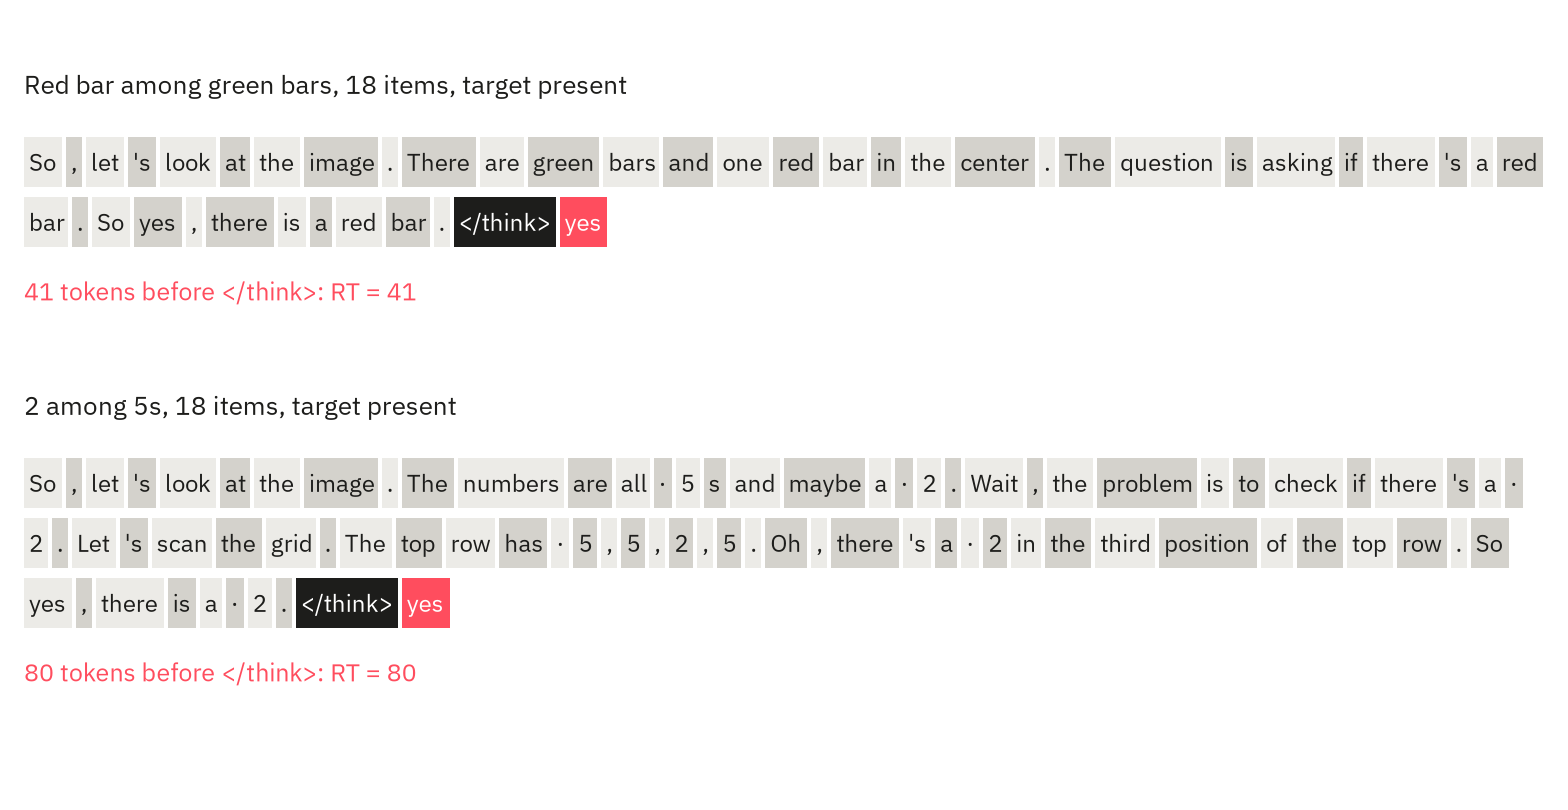

In [1]:
import numpy  as np
import pandas as pd
from IPython.display import Image

import figures

humans = figures.load_humans()
model  = figures.load_model()
figures.token_figure("../img/vlm_tokens.png", model)
Image("../img/vlm_tokens.png")

## Proportion correct (Figure 5)

100 displays per point for the model. For humans, all trials of the 9 people together. In the
feature file, observer "rm" is left out, as in the paper (see `figures.load_humans`).

people: {'2v5': 9, 'feature': 9}
model replies that never closed their thinking: 0
model answers: {'no': 830, 'yes': 770}
   task  present  set_size  mean_model  count_model  mean_humans  count_humans
    2v5        0         3        1.00          100        0.983          4551
    2v5        0         6        1.00          100        0.987          4502
    2v5        0        12        1.00          100        0.988          4492
    2v5        0        18        1.00          100        0.987          4496
    2v5        1         3        1.00          100        0.981          4366
    2v5        1         6        0.95          100        0.982          4572
    2v5        1        12        0.88          100        0.948          4468
    2v5        1        18        0.87          100        0.908          4407
feature        0         3        1.00          100        0.982          4573
feature        0         6        1.00          100        0.984          4589
feature  

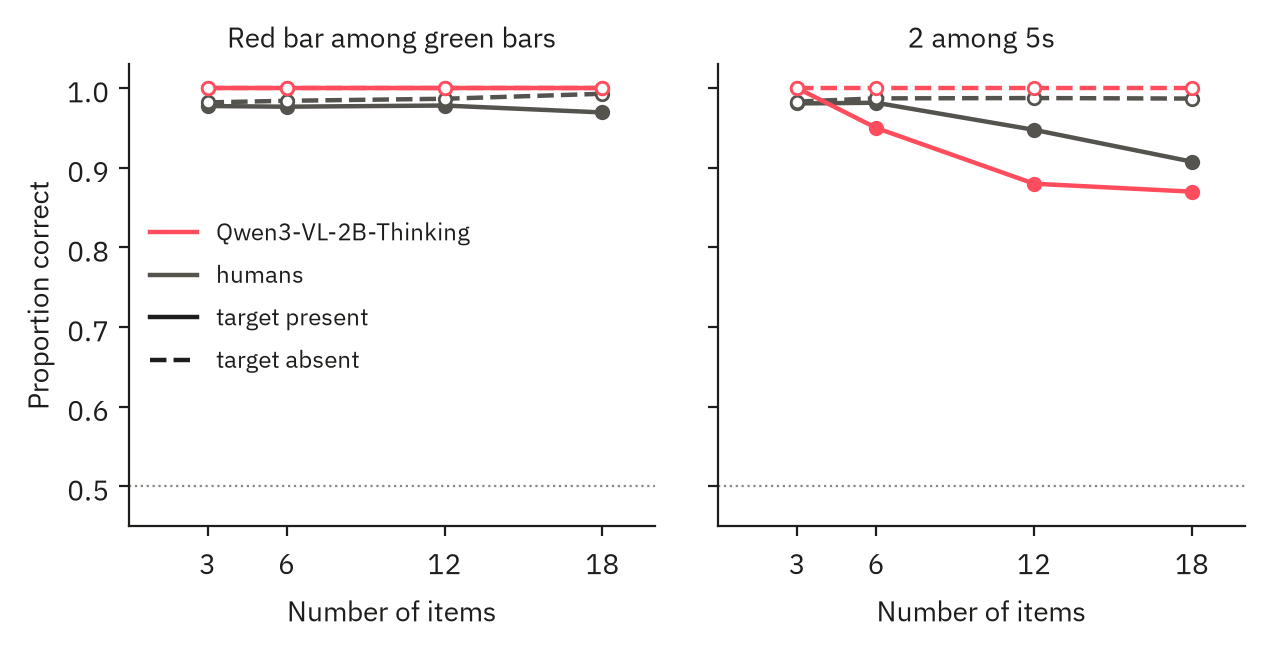

In [2]:
print("people:", humans.groupby("task").subject.nunique().to_dict())
print("model replies that never closed their thinking:", int((model.finished == 0).sum()))
print("model answers:", model.answer.value_counts().to_dict())
a = figures.accuracy(model).merge(figures.accuracy(humans), on=["task", "present", "set_size"],
                                  suffixes=("_model", "_humans"))
print(a.round(3).to_string(index=False))
figures.accuracy_figure("../img/vlm_accuracy.png", model, humans)
Image("../img/vlm_accuracy.png")

## Thinking tokens against the number of items (Figure 6)

Correct displays only, as for the human RTs. The median, because a few replies run on for hundreds
or thousands of tokens.

                          count   50%   mean    max
task    present set_size                           
2v5     0       3         100.0  46.5   57.5  502.0
                6         100.0  53.0   56.9  276.0
                12        100.0  46.0   45.6   72.0
                18        100.0  47.0   49.2   80.0
        1       3         100.0  50.0   51.6  148.0
                6          95.0  58.0   69.1  370.0
                12         88.0  71.5   95.5  461.0
                18         87.0  80.0  117.1  736.0
feature 0       3         100.0  36.0   39.2   60.0
                6         100.0  43.0   40.0   58.0
                12        100.0  43.0   39.6   46.0
                18        100.0  42.0   38.9   51.0
        1       3         100.0  36.0   37.5   86.0
                6         100.0  35.0   35.6   59.0
                12        100.0  41.0   39.0   61.0
                18        100.0  41.0   39.8   67.0

slopes, tokens per item: {('2v5', 0): -0.16, ('2v5', 1): 2.0, (

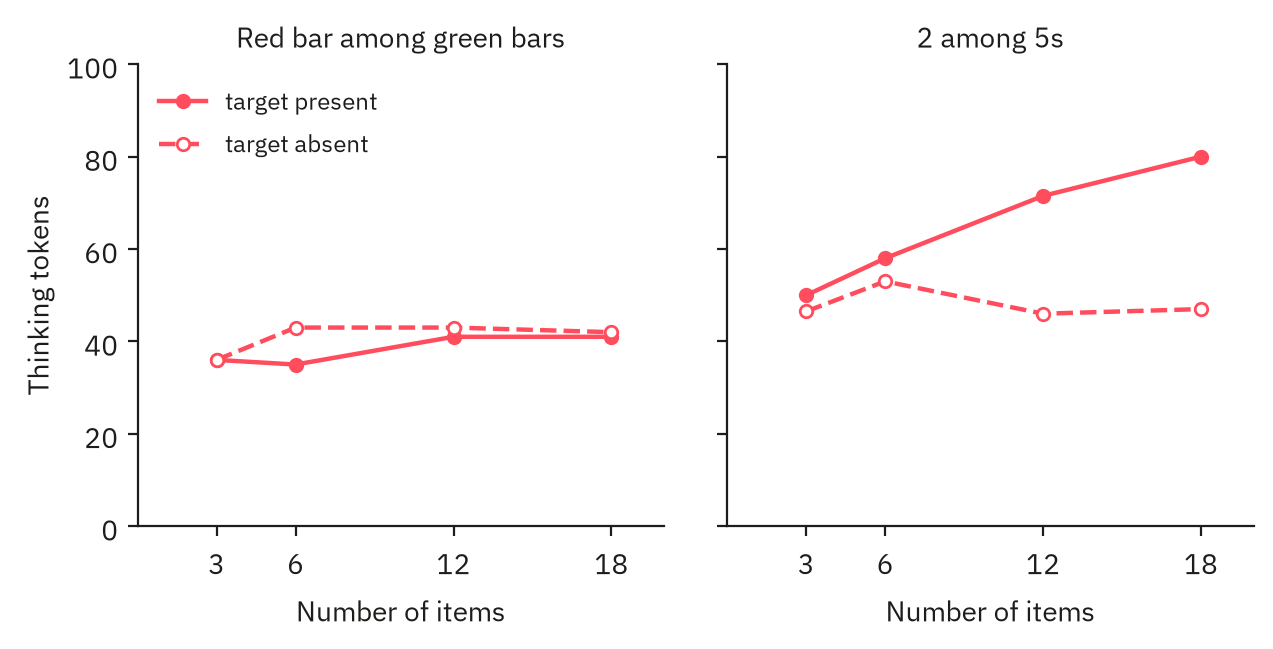

In [3]:
print(model[model.correct == 1].groupby(["task", "present", "set_size"]).rt_tokens
      .describe()[["count", "50%", "mean", "max"]].round(1).to_string())
slopes = figures.slopes(figures.model_rt(model), "median")
print()
print("slopes, tokens per item:", {k: round(v, 2) for k, v in slopes.items()})
figures.model_rt_figure("../img/vlm_rt.png", model)
Image("../img/vlm_rt.png")

## The longest reply

The model lists the same rows again and again.

In [4]:
r = model.loc[model.rt_tokens.idxmax()]
print("%s, %d items, target %s: %d thinking tokens, answer %s"
      % (r.task, r.set_size, "present" if r.present else "absent", r.rt_tokens, r.answer))
print(r.thinking[:1500], "...")

2v5, 12 items, target present: 2793 thinking tokens, answer no
So, let's look at the image. The question is whether there's a 2. Scanning the image, I see multiple 5s, but no 2. The bottom left has a 5 and a 2? Wait, no. Let me check again. The image has rows with 5s. Let's see each cell:

First row: 5 5 5

Second row: 5 5 5

Third row: 5 5 5 (wait, no, the third row is 5 5 5? Wait, no, the third row in the image is a single 5, then 5 on the left, then 5 on the right? Wait, no. Let me visualize the image:

Wait, the image is a grid of 5s. Let's count the 5s. The leftmost column has 5s in each row? Wait, no. Let's list each cell:

Row 1: 5 5 5

Row 2: 5 5 5

Row 3: 5 5 5

Row 4: 5 5 5

Row 5: 5 5 5

Wait, no, the image shows a pattern where some cells have 5s. Wait, no, looking at the user's input:

The image has:

First row: 5 5 5

Second row: 5 5 5

Third row: 5 5 5

Fourth row: 5 5 5

Wait, no, no. Wait, the user's image is:

Top row: 5 5 5 (but maybe the first row has two 5s and a 5

## Human RTs (Figure 2)

Correct trials. The median RT of each person, then the mean over the 9 people (bars: ± 1 SE). With
each person's mean instead of the median, the slopes are the paper's (1.0 and -0.7 ms/item for the
red bar, 43 and 95 ms/item for the 2 among 5s).

   task  present  set_size   mean   sem
    2v5        0         3  755.0  52.0
    2v5        0         6 1124.0  94.0
    2v5        0        12 1752.0 147.0
    2v5        0        18 2142.0 178.0
    2v5        1         3  640.0  39.0
    2v5        1         6  770.0  49.0
    2v5        1        12 1019.0  69.0
    2v5        1        18 1211.0  75.0
feature        0         3  401.0  16.0
feature        0         6  399.0  17.0
feature        0        12  395.0  16.0
feature        0        18  395.0  17.0
feature        1         3  372.0  17.0
feature        1         6  378.0  18.0
feature        1        12  383.0  18.0
feature        1        18  387.0  18.0

slopes, ms per item (medians): {('2v5', 0): 92.7, ('2v5', 1): 38.2, ('feature', 0): -0.4, ('feature', 1): 0.9}
slopes, ms per item (means):   {('2v5', 0): 95.3, ('2v5', 1): 43.1, ('feature', 0): -0.7, ('feature', 1): 1.0}


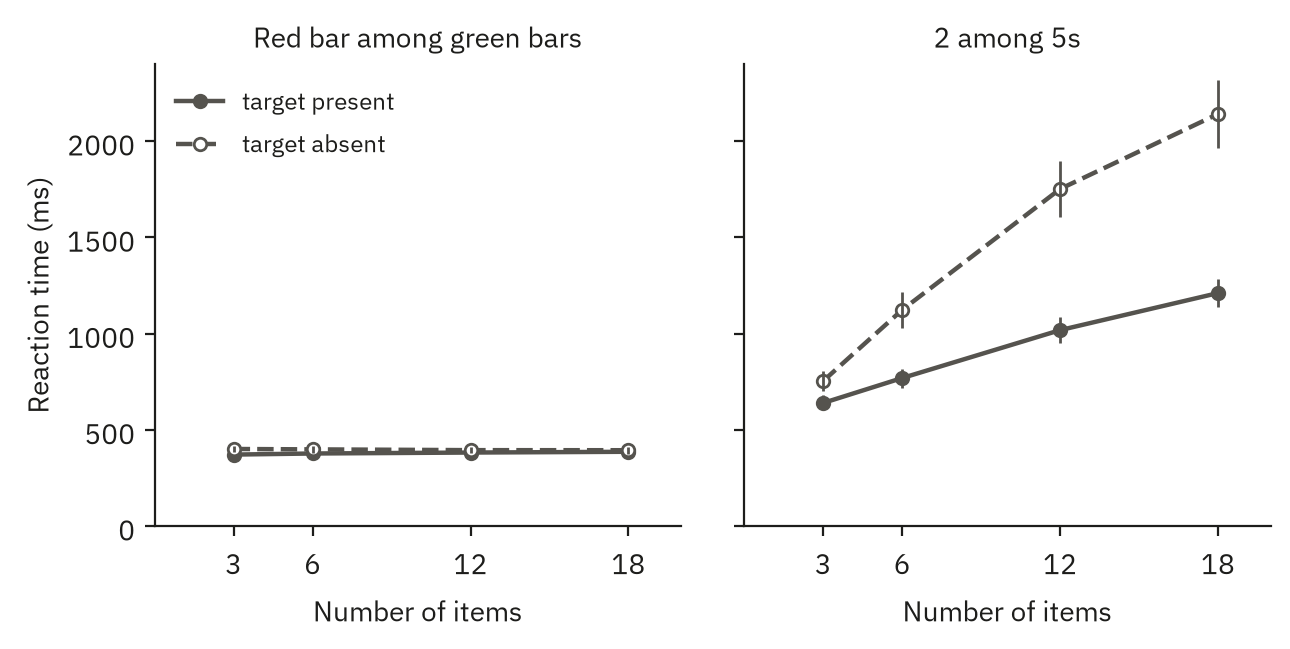

In [5]:
print(figures.human_rt(humans).round(0).to_string(index=False))
print()
print("slopes, ms per item (medians):", {k: round(v, 1) for k, v in figures.slopes(figures.human_rt(humans), "mean").items()})
print("slopes, ms per item (means):  ", {k: round(v, 1) for k, v in figures.slopes(figures.human_rt(humans, "mean"), "mean").items()})
figures.human_rt_figure("../img/human_rt.png", humans)
Image("../img/human_rt.png")

## Absent against present

For people, a 2 among 5s takes about twice as long to call absent as present. For the model it is
the other way round.

In [6]:
h = figures.slopes(figures.human_rt(humans), "mean")
m = figures.slopes(figures.model_rt(model), "median")
print("2 among 5s, slope absent / present:  humans %.1f | model %.1f"
      % (h[("2v5", 0)] / h[("2v5", 1)], m[("2v5", 0)] / m[("2v5", 1)]))

2 among 5s, slope absent / present:  humans 2.4 | model -0.1
